# Chemical evolution of M31 with VICE

**LAPIS 2026 — Dynamics of the Andromeda system**

In this notebook you will:

1. Plot α-element abundances of M31 disk stars measured with JWST (Nidever et al. 2024).
2. Plot M31's star formation history measured from resolved-star photometry (Williams et al. 2017), and see how much it depends on the stellar evolution models used.
3. Run one-zone galactic chemical evolution (GCE) models with **VICE** (Johnson & Weinberg 2020) and learn what the two most important model parameters — the mass-loading factor $\eta$ and the star formation efficiency timescale $\tau_\star$ — do to the predicted [α/Fe]–[Fe/H] track.
4. Compare those model tracks to the M31 data.
5. Change the nucleosynthetic yields to an empirically calibrated set (Weinberg et al. 2024) and see how that changes the comparison.

## 0. Setup

**Installing VICE.** VICE is on PyPI and GitHub ([giganano/VICE](https://github.com/giganano/VICE); [science documentation](https://vice-astro.readthedocs.io/en/latest/science_documentation/index.html)). The simplest route is a pre-built wheel, which exists for **VICE 1.3.0 on Python ≤ 3.10**. On newer Pythons `pip` falls back to compiling from source, which can fail. The safest setup is a dedicated environment:

```bash
conda create -n vice python=3.10
conda activate vice
pip install vice==1.3.0 dill numpy pandas matplotlib jupyter
```

(`dill` lets VICE save the Python function you pass it alongside each model's output.)

**Data files.** This notebook expects a `data/` folder next to it containing `Nidever2024.csv` and the four `Williams17_*.txt` files.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import vice

print("VICE version:", vice.__version__)

DATA = Path("data")            # input data
OUTDIR = Path("vice_outputs")  # VICE writes one <name>.vice directory per model here
OUTDIR.mkdir(exist_ok=True)

# VICE warns that closed-box (eta = 0) models suffer from the G-dwarf problem.
# We run one on purpose below, so silence that one warning.
warnings.filterwarnings("ignore", message="Closed-box GCE models")

# Plot styling: one fixed colour per series, data in neutral grey
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
DATA_COLOR = "#52514e"
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.6,
    "legend.frameon": False,
})

VICE version: 1.3.0


## 1. The data: α-abundances of M31 disk stars (Nidever et al. 2024)

Nidever et al. (2024, IAU Symp. 377, 115) measured metallicities and α-element abundances for red giant branch stars in a single JWST/NIRSpec field in M31's disk, at a projected distance of 18 kpc from the center. The file contains two columns, **[Fe/H]** and **[α/Fe]**, with no header row.

The spectra cover 0.9–1.8 μm (NIRSpec G140H/F100LP), and [α/Fe] is measured as a *single* parameter in which all α-elements are scaled together. Our default comparison is to model **[Mg/Fe]**: Mg has some of the strongest α-element lines at these wavelengths, and it is made almost entirely by core-collapse supernovae, which makes it the cleanest element to model. You can switch the model element to O later and see how much it matters.

In [2]:
nid = pd.read_csv(DATA / "Nidever2024.csv", header=None, names=["fe_h", "alpha_fe"])
print(f"{len(nid)} stars")
nid.describe().loc[["min", "50%", "max"]]

75 stars


,fe_h,alpha_fe
min,-0.354286,-0.195754
50%,0.175584,0.089809
max,0.495584,0.340340


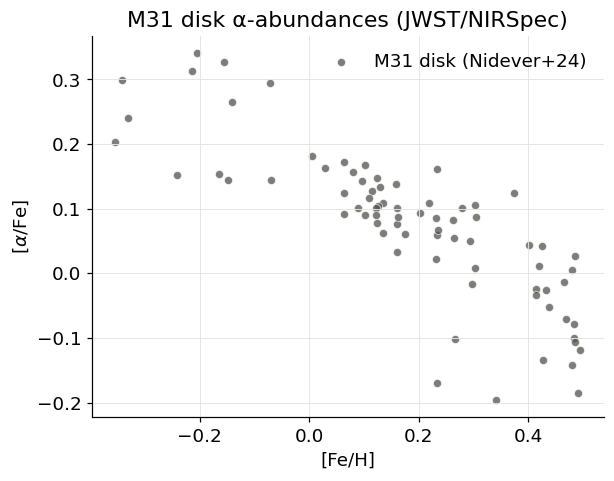

In [3]:
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(nid["fe_h"], nid["alpha_fe"], s=28, color=DATA_COLOR, alpha=0.75,
           edgecolor="white", linewidth=0.5, label="M31 disk (Nidever+24)")
ax.set_xlabel("[Fe/H]")
ax.set_ylabel(r"[$\alpha$/Fe]")
ax.set_title("M31 disk α-abundances (JWST/NIRSpec)")
ax.legend(loc="upper right")
plt.show()

**What to notice:** the stars form a *single*, declining sequence in [α/Fe] with metallicity — there is no separate low-α and high-α population like the Milky Way's thin and thick disks. Nidever et al. note the sequence resembles the Milky Way's *high-α* sequence, which formed during an epoch of rapid star formation.

## 2. M31's star formation history (Williams et al. 2017)

Williams et al. (2017) derived the star formation history (SFH) of M31's disk by fitting color–magnitude diagrams from the PHAT survey. Fitting a CMD requires a set of stellar evolution models (isochrones), and different model sets give different answers. Table 9 of the paper lists the total SFR in each age bin for four model sets: **MIST, Padova, PARSEC and BaSTI**.

Each file lists the lookback-time bin edges (yr), the SFR (M$_\odot$ yr$^{-1}$), and its upper/lower uncertainties. The rates are for the PHAT footprint; multiply by 3 to scale to all of M31 (set `SCALE = 3` below).

In [4]:
SCALE = 1   # set to 3 to scale from the PHAT footprint to the whole of M31

def read_williams(path):
    # Return bin edges (Gyr, ascending lookback time), SFR, +err, -err.
    d = np.loadtxt(path)                    # lines starting with '#' are skipped
    d = d[np.argsort(d[:, 1])]              # sort by the young edge of each bin
    edges = np.append(d[:, 1], d[-1, 0]) / 1e9
    return edges, SCALE * d[:, 2], SCALE * d[:, 3], SCALE * d[:, 4]

sfh_models = ["MIST", "Padova", "PARSEC", "BASTI18"]
sfh = {m: read_williams(DATA / f"Williams17_{m}.txt") for m in sfh_models}

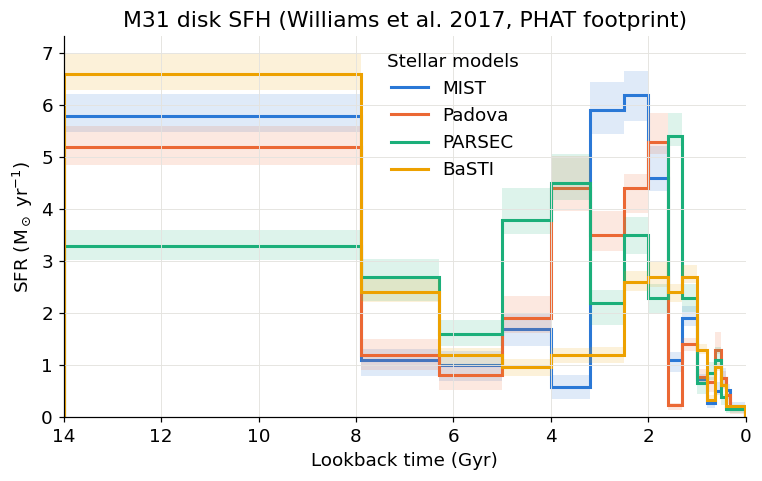

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for m, col in zip(sfh_models, COLORS):
    edges, sfr, ep, em = sfh[m]
    ax.stairs(sfr + ep, edges, baseline=sfr - em, fill=True, color=col, alpha=0.15)
    ax.stairs(sfr, edges, color=col, linewidth=2,
              label=m.replace("BASTI18", "BaSTI"))
ax.set_xlabel("Lookback time (Gyr)")
ax.set_ylabel(r"SFR (M$_\odot$ yr$^{-1}$)")
ax.set_xlim(14, 0)   # oldest stars on the left, present day on the right
ax.set_ylim(0, None)
ax.set_title("M31 disk SFH (Williams et al. 2017, PHAT footprint)")
ax.legend(title="Stellar models", loc="upper center", bbox_to_anchor=(0.57, 1.0))
plt.show()

**What to notice:**

* All four model sets agree that a large fraction of the stars formed in the oldest bin (> 8 Gyr ago).
* All four show enhanced star formation between roughly 1 and 5 Gyr ago, but its **timing and amplitude depend on the stellar models**: MIST peaks at 2–3 Gyr, Padova is broad over 1.6–4 Gyr, PARSEC peaks at 1.3–1.6 Gyr, and BaSTI is the most muted. The spread between the curves is a *systematic* uncertainty that the quoted error bars do not capture.

We will not use these SFHs in the models yet — first we build intuition with the simplest possible SFH.

## 3. One-zone chemical evolution in a nutshell

A one-zone model treats the star-forming gas as a single, instantaneously mixed reservoir. Its gas mass evolves as

$$\dot M_g = \dot M_{\rm in} - \dot M_\star - \dot M_{\rm out} + \dot M_r ,$$

(inflow − star formation − outflow + gas returned by stars). Two parameters control almost everything about the shape of the [α/Fe]–[Fe/H] track (Weinberg et al. 2017):

| Parameter | Definition | Physical meaning |
|---|---|---|
| SFE timescale $\tau_\star$ | $\tau_\star = M_g / \dot M_\star$ | How quickly gas is turned into stars. Star formation efficiency is SFE $= 1/\tau_\star$. **Short $\tau_\star$ = high SFE.** |
| Mass-loading factor $\eta$ | $\eta = \dot M_{\rm out} / \dot M_\star$ | How much gas is ejected per unit mass of stars formed. |

The third ingredient is the **nucleosynthetic yields**: how much Mg and Fe core-collapse supernovae (CCSNe, prompt) and Type Ia supernovae (SNe Ia, delayed by ~0.1–10 Gyr) return per unit mass of stars formed.

The key physics of the track:

* **Early on**, only CCSNe have exploded, so [Mg/Fe] sits on a **plateau** set by the CCSN yield ratio $y^{\rm CC}_{\rm Mg} / y^{\rm CC}_{\rm Fe}$.
* Once SNe Ia start contributing Fe, [Mg/Fe] **declines** — the "knee". *Where* in [Fe/H] the knee happens depends on how much enrichment the galaxy achieved before SNe Ia turned on, i.e. on $\tau_\star$ (and $\eta$).
* At late times, for a constant SFR, the abundances approach an **equilibrium** where new metal production balances dilution by inflow and loss to star formation and outflows: $Z_{\rm eq} \approx y / (1 + \eta - r)$, with $r \approx 0.4$ the recycled fraction. **$\eta$ sets the final metallicity.**

### VICE's default yields
For now we use VICE's built-in default yields: Limongi & Chieffi (2018) for CCSNe and Seitenzahl et al. (2013) N1 for SNe Ia, with a $t^{-1.1}$ SN Ia delay-time distribution and a 150 Myr minimum delay. These are theoretical yields; **we will replace them with an empirically calibrated set in Section 6.**

VICE stores the yields as global settings (`vice.yields.ccsne.settings` and `vice.yields.sneia.settings`): every model you run uses whatever values are set at that moment. The cell below saves the defaults so we can restore them later.

In [6]:
ELEMENTS = ("fe", "mg", "o")
DEFAULT_YIELDS = {el: (vice.yields.ccsne.settings[el], vice.yields.sneia.settings[el])
                  for el in ELEMENTS}

def restore_default_yields():
    for el, (y_cc, y_ia) in DEFAULT_YIELDS.items():
        vice.yields.ccsne.settings[el] = y_cc
        vice.yields.sneia.settings[el] = y_ia

print(f"{'element':>8} {'y_CC':>10} {'y_Ia':>10} {'Z_sun':>10}")
for el in ELEMENTS:
    print(f"{el:>8} {vice.yields.ccsne.settings[el]:10.2e} "
          f"{vice.yields.sneia.settings[el]:10.2e} {vice.solar_z[el]:10.2e}")

ALPHA = "mg"   # alpha element compared with the data; also try "o"
plateau = np.log10(vice.yields.ccsne.settings[ALPHA] / vice.yields.ccsne.settings["fe"]) \
        - np.log10(vice.solar_z[ALPHA] / vice.solar_z["fe"])
print(f"\nExpected CCSN-only plateau: [{ALPHA.capitalize()}/Fe] = {plateau:+.2f}")

 element       y_CC       y_Ia      Z_sun
      fe   2.46e-04   2.58e-03   1.29e-03
      mg   4.97e-04   8.83e-06   7.06e-04
       o   5.64e-03   5.79e-05   5.72e-03

Expected CCSN-only plateau: [Mg/Fe] = +0.57


### Running a VICE model

We use `vice.singlezone` in `mode="sfr"`: we tell VICE the star formation rate as a function of time, and it works out the gas mass ($M_g = \tau_\star \dot M_\star$) and the inflow rate needed to sustain it.

For this first set of models the SFH is **constant**. Its normalization does not matter for abundance ratios — only its *shape* does — so we simply use 1 M$_\odot$ yr$^{-1}$. Each model runs for 13.5 Gyr with a 10 Myr timestep.

The two helper functions below run a model and plot a set of models against the data. Read through them: `run_model` is all you need to run VICE.

In [7]:
TIMES = np.linspace(0, 13.5, 1351)   # output times (Gyr)

def constant_sfr(t):
    # Constant star formation rate (Msun/yr); t is time in Gyr
    return 1.0

def run_model(name, tau_star, eta, sfr_func=constant_sfr):
    # Run a one-zone VICE model and return its output object.
    sz = vice.singlezone(
        name=str(OUTDIR / name),     # output written to vice_outputs/<name>.vice
        func=sfr_func,
        mode="sfr",                  # func gives the SFR (Msun/yr)
        tau_star=tau_star,           # SFE timescale (Gyr)
        eta=eta,                     # mass-loading factor
        elements=ELEMENTS,
        dt=0.01,                     # timestep (Gyr)
    )
    sz.run(TIMES, overwrite=True)
    return vice.output(str(OUTDIR / name))


def plot_tracks(outputs, labels, title, legend_title, alpha=None):
    # Left: [alpha/Fe] vs [Fe/H] with the M31 data. Right: [Fe/H] vs time.
    # Dots on each track mark every 1 Gyr: with a constant SFR, an equal number
    # of stars forms between consecutive dots.
    alpha = alpha or ALPHA
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8),
                                   gridspec_kw={"width_ratios": [1.25, 1]})
    ax1.scatter(nid["fe_h"], nid["alpha_fe"], s=22, color=DATA_COLOR, alpha=0.6,
                edgecolor="white", linewidth=0.5, label="M31 disk (Nidever+24)", zorder=3)

    for out, lab, col in zip(outputs, labels, COLORS):
        h = out.history
        t = np.array(h["time"])
        feh = np.array(h["[fe/h]"])
        afe = np.array(h[f"[{alpha}/fe]"])
        ax1.plot(feh, afe, color=col, lw=2, label=lab, zorder=2)
        ticks = [np.argmin(np.abs(t - tt)) for tt in range(1, 14)]
        ax1.plot(feh[ticks], afe[ticks], "o", ms=4.5, color=col, mec="white", mew=0.8, zorder=2)
        ax2.plot(t, feh, color=col, lw=2, label=lab)

    ax1.set(xlim=(-2.0, 0.8), ylim=(-0.65, 0.8),
            xlabel="[Fe/H]",
            ylabel=f"[α/Fe]  (model: [{alpha.capitalize()}/Fe])")
    ax1.legend(title=legend_title, loc="lower left", fontsize=10)
    ax2.set(xlim=(0, 13.5), ylim=(-2.0, 0.8), xlabel="Time (Gyr)", ylabel="[Fe/H]")
    ax2.axhspan(nid["fe_h"].min(), nid["fe_h"].max(), color=DATA_COLOR, alpha=0.1, lw=0)
    ax2.text(0.3, nid["fe_h"].max() - 0.04, "range of data", ha="left", va="top",
             fontsize=9, color=DATA_COLOR)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


def summarize(outputs, labels, alpha=None):
    # Table of [Fe/H] and [alpha/Fe] at a few times
    alpha = alpha or ALPHA
    rows = {}
    for out, lab in zip(outputs, labels):
        h = out.history
        t = np.array(h["time"])
        row = {}
        for tt in [1, 3, 13.5]:
            i = np.argmin(np.abs(t - tt))
            row[("[Fe/H]", f"{tt:g} Gyr")] = round(h["[fe/h]"][i], 2)
            row[(f"[{alpha.capitalize()}/Fe]", f"{tt:g} Gyr")] = round(h[f"[{alpha}/fe]"][i], 2)
        rows[lab] = row
    df = pd.DataFrame(rows).T
    return df[sorted(df.columns, key=lambda c: c[0] != "[Fe/H]")]

## 4. Experiment 1: varying the mass-loading factor $\eta$

Fix the SFE timescale at VICE's default, $\tau_\star = 2$ Gyr, and run three models with $\eta = 0$ (a closed box: no outflows), 5 and 10.

In [8]:
TAU_FIXED = 2.0                  # Gyr
eta_values = [0, 5, 10]

eta_models = [run_model(f"const_tau{TAU_FIXED:g}_eta{eta:g}", TAU_FIXED, eta)
              for eta in eta_values]
eta_labels = [f"η = {eta:g}" for eta in eta_values]

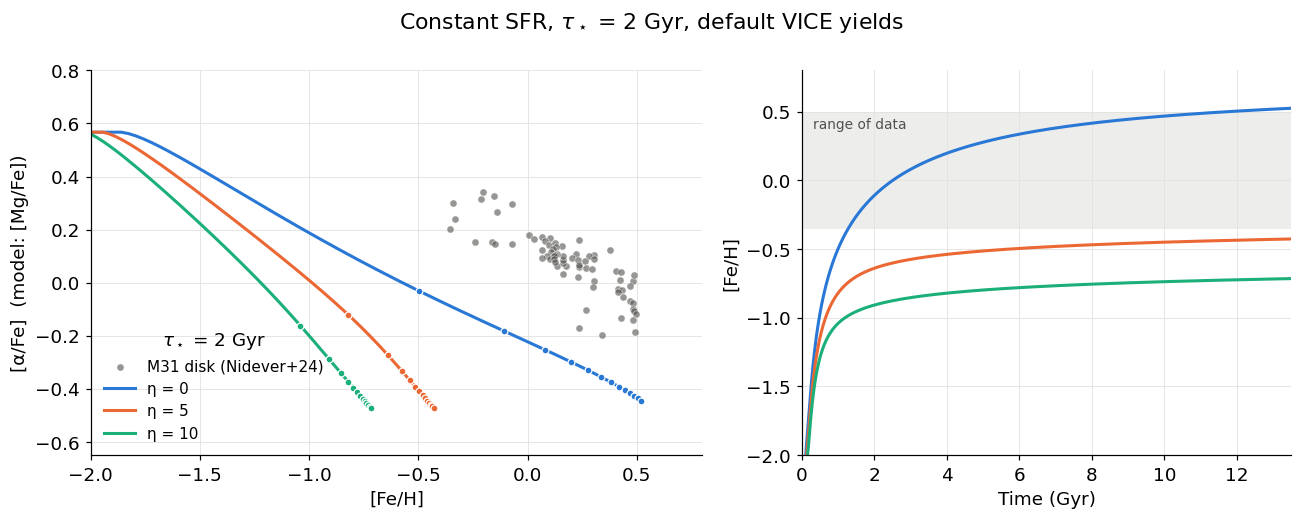

[Fe/H]                [Mg/Fe]               
        1 Gyr 3 Gyr 13.5 Gyr   1 Gyr 3 Gyr 13.5 Gyr
η = 0   -0.50  0.08     0.52   -0.03 -0.25    -0.45
η = 5   -0.82 -0.57    -0.43   -0.12 -0.33    -0.47
η = 10  -1.04 -0.85    -0.71   -0.16 -0.34    -0.48

In [9]:
plot_tracks(eta_models, eta_labels,
            title=rf"Constant SFR, $\tau_\star$ = {TAU_FIXED:g} Gyr, default VICE yields",
            legend_title=rf"$\tau_\star$ = {TAU_FIXED:g} Gyr")
summarize(eta_models, eta_labels)

**What to notice:**

* All three tracks start on the **same plateau** and fall toward the **same late-time [Mg/Fe]**. Outflows remove Mg and Fe in the same proportion as they are present in the gas, so $\eta$ cannot change abundance *ratios* directly.
* $\eta$ sets **how far in [Fe/H]** the galaxy gets: stronger outflows mean a lower equilibrium metallicity (right panel). The closed box ($\eta = 0$) keeps enriching until it reaches the most metal-rich M31 stars, while the $\eta = 5$ and $\eta = 10$ models never reach the metallicity of *any* star in the data.
* Because the tracks are stretched or compressed in [Fe/H], $\eta$ also moves the **knee**: with more outflow, the galaxy has reached a lower [Fe/H] by the time SNe Ia turn on.
* Look at the 1-Gyr dots. With a constant SFR, most stars form after the track has flattened, so the models predict that most stars should sit at the low-[Mg/Fe], metal-rich end.

## 5. Experiment 2: varying the star formation efficiency

Now fix the mass-loading factor at VICE's default, $\eta = 2.5$, and vary the SFE timescale: $\tau_\star$ = 0.5 Gyr (high SFE), 2 Gyr and 10 Gyr (low SFE).

In [10]:
ETA_FIXED = 2.5
tau_values = [0.5, 2, 10]        # Gyr

tau_models = [run_model(f"const_eta{ETA_FIXED:g}_tau{tau:g}", tau, ETA_FIXED)
              for tau in tau_values]
tau_labels = [f"τ★ = {tau:g} Gyr" for tau in tau_values]

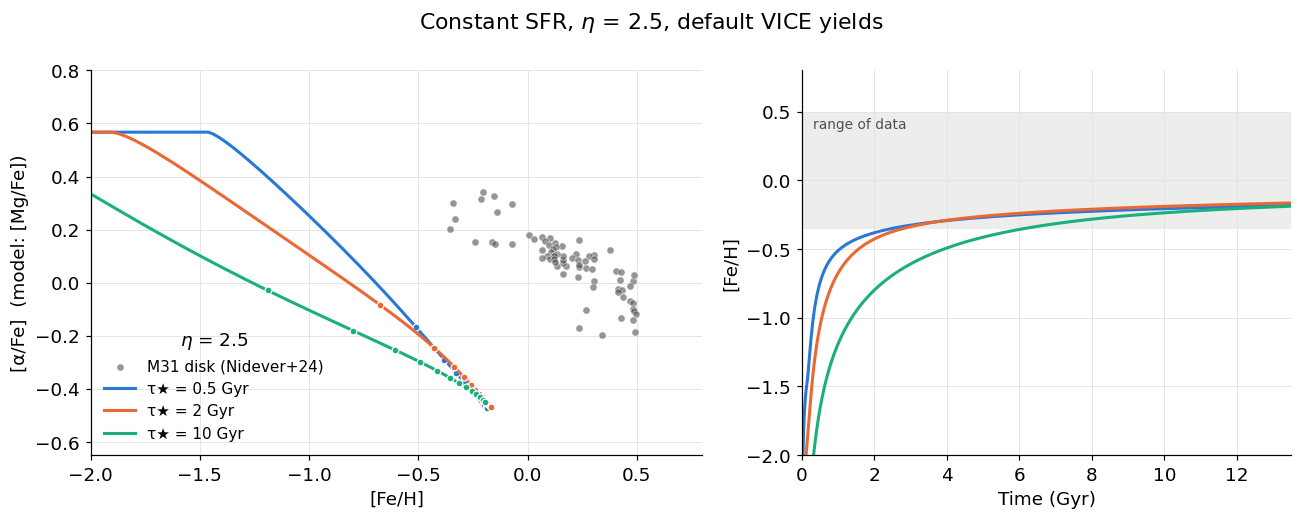

[Fe/H]                [Mg/Fe]               
              1 Gyr 3 Gyr 13.5 Gyr   1 Gyr 3 Gyr 13.5 Gyr
τ★ = 0.5 Gyr  -0.51 -0.33    -0.18   -0.17 -0.34    -0.48
τ★ = 2 Gyr    -0.67 -0.34    -0.16   -0.08 -0.32    -0.47
τ★ = 10 Gyr   -1.19 -0.61    -0.19   -0.03 -0.25    -0.45

In [11]:
plot_tracks(tau_models, tau_labels,
            title=rf"Constant SFR, $\eta$ = {ETA_FIXED:g}, default VICE yields",
            legend_title=rf"$\eta$ = {ETA_FIXED:g}")
summarize(tau_models, tau_labels)

**What to notice:**

* All three models converge to the **same final [Fe/H]**: for a constant SFR, the equilibrium metallicity depends on $\eta$ and the yields, not on $\tau_\star$.
* $\tau_\star$ controls **how fast** the galaxy gets there (right panel) and therefore **where the knee falls**. With high SFE ($\tau_\star = 0.5$ Gyr) the gas is enriched to high [Fe/H] before SNe Ia contribute, so [Mg/Fe] stays elevated to higher metallicity. With low SFE ($\tau_\star = 10$ Gyr) the knee happens at very low [Fe/H].
* The M31 stars retain elevated [α/Fe] up to [Fe/H] ~ 0, which in this framework points to **efficient, rapid star formation** — consistent with Nidever et al.'s comparison to the Milky Way's high-α sequence.
* **None of the models in either experiment passes through the data.** Wherever a track reaches the data's metallicity range, its [Mg/Fe] is ~0.3 dex below the observed [α/Fe], and every model's late-time [Mg/Fe] (≈ −0.45) is far below the most α-poor M31 stars (≈ −0.2). Neither $\eta$ nor $\tau_\star$ can move that floor: it is set by the ratio of the total Mg and Fe yields. **To change it, we have to change the yields** — the subject of the next section.

## 6. Changing the yields: an empirically calibrated yield set

Sections 4 and 5 showed that $\tau_\star$ and $\eta$ cannot move the [α/Fe] plateau or the late-time [α/Fe] — the yields set both. Here we replace VICE's theoretical defaults with yields built following **Weinberg et al. (2024, hereafter W24)**, the framework used by Escala et al. (2026) for the Magellanic Clouds. Instead of taking yields from supernova models, W24 calibrate them empirically in three steps:

1. **Absolute scale.** The mean Fe mass ejected per core-collapse supernova has been measured from supernova light curves (0.058 M$_\odot$; Rodríguez et al. 2023). Integrated over the IMF, this implies a CCSN Mg yield of $y^{\rm CC}_{\rm Mg} \approx 6.5 \times 10^{-4}$, close to the solar Mg abundance. Following Escala et al. (2026), we fix $y^{\rm CC}_{\rm Mg} = 6.56 \times 10^{-4}$ and $y^{\rm Ia}_{\rm Mg} = 0$.

2. **CCSN Fe (and O) yields from the [α/Fe] plateau.** The plateau measures the CCSN yield ratio:
$$[{\rm Mg/Fe}]_{\rm CC} = \log_{10}\left(\frac{y^{\rm CC}_{\rm Mg}}{y^{\rm CC}_{\rm Fe}}\right) - \log_{10}\left(\frac{Z_{\rm Mg,\odot}}{Z_{\rm Fe,\odot}}\right).$$
W24 assume O has the same plateau as Mg and, like Mg, comes only from CCSNe, so we set $y^{\rm CC}_{\rm O}$ from the same equation and $y^{\rm Ia}_{\rm O} = 0$. We use VICE's solar abundances, so the plateau lands exactly where we put it on our plots.

3. **SN Ia Fe yield from the late-time equilibrium.** Once star formation has gone on long enough, [α/Fe] settles at an equilibrium value $[\alpha/{\rm Fe}]_{\rm eq}$. The drop from the plateau to equilibrium measures how much Fe SNe Ia add relative to CCSNe (W24, Eq. 21):
$$y^{\rm Ia}_{\rm Fe} = \frac{y^{\rm CC}_{\rm Fe}}{\mu}\left(10^{\,[\alpha/{\rm Fe}]_{\rm CC} - [\alpha/{\rm Fe}]_{\rm eq}} - 1\right),$$
where $\mu \approx 1.1$ is an order-unity correction for the SN Ia delay-time distribution and the shape of the SFH.

We follow Escala et al. (2026) and adopt $[\alpha/{\rm Fe}]_{\rm CC} = $ **0.45** and $[\alpha/{\rm Fe}]_{\rm eq} = $ **0**, both calibrated on the Milky Way.

In [12]:
Y_MG_CC = 6.56e-4   # absolute yield scale (W24; Escala et al. 2026)
MU = 1.1            # W24 correction factor

def set_w24_yields(alpha_cc=0.45, alpha_eq=0.0):
    # Set VICE's Mg, O and Fe yields following Weinberg et al. (2024)
    zsun = vice.solar_z
    y_fe_cc = Y_MG_CC / (10**alpha_cc * zsun["mg"] / zsun["fe"])
    y_o_cc = y_fe_cc * 10**alpha_cc * zsun["o"] / zsun["fe"]
    y_fe_ia = y_fe_cc / MU * (10**(alpha_cc - alpha_eq) - 1)
    vice.yields.ccsne.settings["mg"] = Y_MG_CC
    vice.yields.sneia.settings["mg"] = 0.0
    vice.yields.ccsne.settings["o"] = y_o_cc
    vice.yields.sneia.settings["o"] = 0.0
    vice.yields.ccsne.settings["fe"] = y_fe_cc
    vice.yields.sneia.settings["fe"] = y_fe_ia

def yield_table():
    return {f"y_{el.capitalize()}^{ch}": settings[el]
            for el in ["mg", "o", "fe"]
            for ch, settings in [("CC", vice.yields.ccsne.settings), ("Ia", vice.yields.sneia.settings)]}

ALPHA_CC, ALPHA_EQ = 0.45, 0.0

restore_default_yields()
table = {"VICE default": yield_table()}
set_w24_yields(ALPHA_CC, ALPHA_EQ)
table[f"W24 ([α/Fe]_CC = {ALPHA_CC}, [α/Fe]_eq = {ALPHA_EQ:g})"] = yield_table()
restore_default_yields()

pd.DataFrame(table).style.format("{:.2e}")

,VICE default,"W24 ([α/Fe]_CC = 0.45, [α/Fe]_eq = 0)"
y_Mg^CC,4.97e-04,6.56e-04
y_Mg^Ia,8.83e-06,0.00e+00
y_O^CC,5.64e-03,5.31e-03
y_O^Ia,5.79e-05,0.00e+00
y_Fe^CC,2.46e-04,4.25e-04
y_Fe^Ia,2.58e-03,7.03e-04


Compared with the defaults, the W24 yields have a **lower plateau** (+0.45 for both Mg and O, instead of +0.57 for Mg and +0.71 for O) and a **~4× smaller SN Ia Fe yield**.

Now run the same model twice — once with each yield set — so that the yields are the only difference. The yields are global, so we set them immediately before the run and restore the defaults afterward. We use $\tau_\star = 1$ Gyr and $\eta = 0$: with the W24 absolute yield scale, even modest outflows keep the model below the metallicities of most M31 stars.

In [13]:
TAU_Y, ETA_Y = 1.0, 0.0

restore_default_yields()
default_model = run_model(f"default_tau{TAU_Y:g}_eta{ETA_Y:g}", TAU_Y, ETA_Y)

set_w24_yields(ALPHA_CC, ALPHA_EQ)
w24_model = run_model(f"w24_cc{ALPHA_CC:g}_eq{ALPHA_EQ:g}_tau{TAU_Y:g}_eta{ETA_Y:g}", TAU_Y, ETA_Y)
restore_default_yields()

yield_models = [default_model, w24_model]
yield_labels = ["VICE default yields", "W24 yields"]

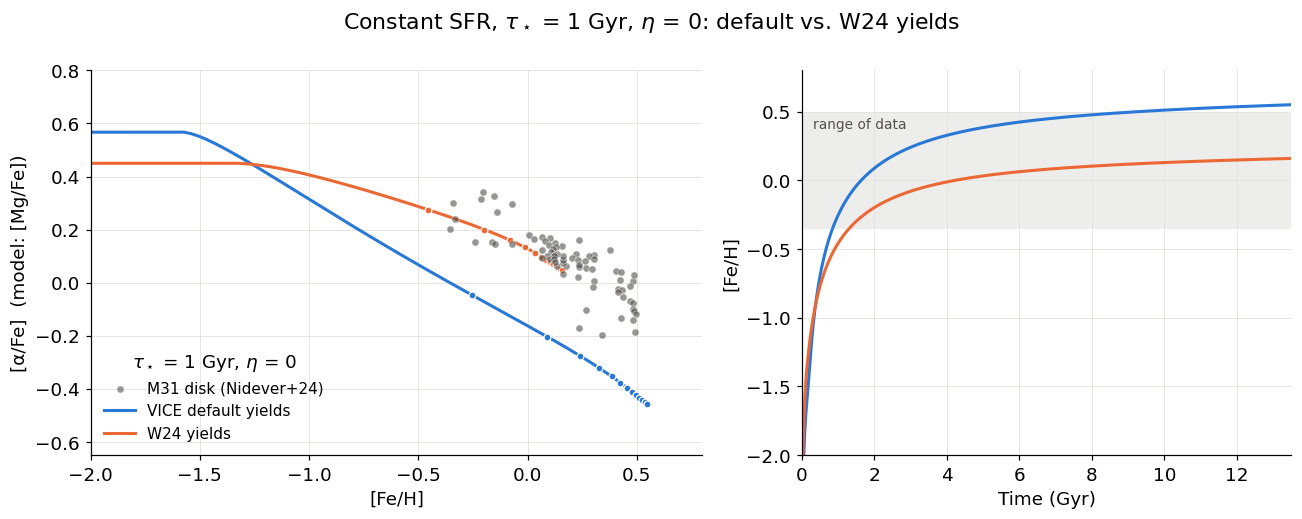

[Fe/H]                [Mg/Fe]               
                     1 Gyr 3 Gyr 13.5 Gyr   1 Gyr 3 Gyr 13.5 Gyr
VICE default yields  -0.25  0.24     0.55   -0.05 -0.28    -0.46
W24 yields           -0.46 -0.08     0.16    0.28  0.16     0.04

In [14]:
plot_tracks(yield_models, yield_labels,
            title=rf"Constant SFR, $\tau_\star$ = {TAU_Y:g} Gyr, $\eta$ = {ETA_Y:g}: default vs. W24 yields",
            legend_title=rf"$\tau_\star$ = {TAU_Y:g} Gyr, $\eta$ = {ETA_Y:g}")
summarize(yield_models, yield_labels)

**What to notice:**

* The W24 track starts on a lower plateau and declines **much more gently**, settling near [α/Fe] ≈ 0 instead of ≈ −0.45. That shallower decline is the smaller SN Ia Fe yield at work.
* With the same $\tau_\star$ and $\eta$, the W24 model reaches a **lower final [Fe/H]**, because its total Fe yield is smaller. The absolute yield scale and $\eta$ are degenerate: both set the equilibrium metallicity.
* **Against the data:** the W24 model runs through the core of the M31 sequence, a large improvement over the default yields. It misses the metal-rich, α-poor tail ([Fe/H] ≳ +0.3, [α/Fe] < 0). A constant-SFR model cannot get below its equilibrium [α/Fe]; a *declining* SFH can, because SNe Ia from the many old stars keep adding Fe while the current star formation rate (and hence CCSN rate) is low. Section 2 showed that M31 formed many of its stars early.
* With `ALPHA = "o"`, the W24 [O/Fe] track is almost identical to [Mg/Fe]: in this framework both elements come from CCSNe with the same plateau. (The small differences come from VICE's default AGB-star yields, which we did not change.)

## 7. Discussion questions

1. Why can't the mass-loading factor alone change the [α/Fe] plateau or the late-time [α/Fe] value? Which model ingredient *does* set them?
2. Compare the highest and lowest [α/Fe] values in the data to the plateau and late-time values of the default-yield models in Sections 4 and 5. What does that tell you about VICE's default yields for M31?
3. Set `ALPHA = "o"` and re-run the notebook. How different are the [O/Fe] and [Mg/Fe] tracks with the default yields? With the W24 yields? The NIRSpec [α/Fe] is a single parameter fit over 0.9–1.8 μm. Which model element is the fairest comparison, and why?
4. In Section 6, the W24 model reaches a lower [Fe/H] than the default-yield model with the same $\eta$. Why? What does this tell you about the degeneracy between the yields and $\eta$?
5. Using the W24 yields, which combination of $\tau_\star$ and $\eta$ gives the best visual match to the data? Is the answer unique?
6. The most α-poor M31 stars reach [α/Fe] ≈ −0.2, below the W24 equilibrium value of 0. Name two ways a model could produce them: one involving the yields, and one involving the SFH. Try an exponentially declining SFH, e.g. `sfr_func=lambda t: np.exp(-t / 3)`.
7. The dots on each track show where stars form. Does the *distribution* of M31 stars along the sequence look like what a constant SFR predicts?
8. Section 2 showed that M31's measured SFH is *not* constant. How would an extended period of enhanced star formation 1–4 Gyr ago change the track?